# Line Detection with the Hough Transform

Edge detection gives a set of edge pixels, but not lines. The **Hough transform** finds straight lines among the edge pixels by voting. It is the standard tool for finding lines in an image, and it is the step that turns the edges from the previous notebooks into the lane markings of a road.

This notebook does the following on two photos:
1. Explains how the Hough transform represents a line and how the votes work.
2. Finds lines with `cv2.HoughLines` on Canny edges.
3. Shows how the threshold controls how many lines are found.
4. Reads the angle of each line.
5. Saves all results to `output/`.

## 1. Imports

- `cv2` (OpenCV): image I/O, Canny edges and the Hough transform
- `matplotlib`: displaying images
- `numpy`: array operations
- `pathlib`: file paths that work on any OS

In [1]:
from pathlib import Path

import cv2
import matplotlib.pyplot as plt
import numpy as np

plt.rcParams["figure.dpi"] = 80  # keeps the saved notebook small

## 2. How the Hough transform works

A line in the image can be written as $y = m\,x + c$. This form fails for vertical lines, because $m$ is infinite. The Hough transform therefore uses the **polar** form of a line:

$$\rho = x\cos\theta + y\sin\theta$$

Here $\rho$ is the distance from the image origin (top-left corner) to the line, and $\theta$ is the angle of the normal to the line. Every pair $(\rho, \theta)$ describes exactly one line, and every line has exactly one pair.

The **voting** works as follows:
1. Each edge pixel $(x, y)$ is a candidate for many lines, one for each angle $\theta$. For each $\theta$ it gives one $\rho$, so it traces a curve in the $(\rho, \theta)$ plane.
2. Edge pixels that lie on the **same line** produce curves that cross at the same $(\rho, \theta)$.
3. A grid of counters, the **accumulator**, records how many curves pass through each $(\rho, \theta)$ cell.
4. Every cell with at least `threshold` votes is reported as a line. The threshold is the minimum number of edge pixels that must lie on a line.

The accuracy is set by the grid: `rho` is the distance step in pixels, and `theta` is the angle step in radians.

## 3. Configuration

- `INPUT_PATHS`: the two photos. `horizontal_vertical.jpg` has clear horizontal and vertical structures. `calendar.jpg` has a grid of lines.
- `CANNY_THRESHOLDS`: the edge thresholds. The Hough transform works on the Canny edge image.
- `RHO_STEP`, `THETA_STEP`: the accuracy of the accumulator grid. A distance step of 1 pixel and an angle step of 1 degree.
- `DEFAULT_THRESHOLD`: the minimum number of votes for the main results.
- `THRESHOLDS_TO_TRY`: several values, to show how the threshold changes the result.
- All results are saved to `OUTPUT_DIR`.

In [2]:
INPUT_PATHS = [Path("horizontal_vertical.jpg"), Path("calendar.jpg")]
OUTPUT_DIR = Path("output")

CANNY_THRESHOLDS = (50, 200)
RHO_STEP = 1
THETA_STEP = np.pi / 180  # 1 degree

DEFAULT_THRESHOLD = 300
THRESHOLDS_TO_TRY = (200, 300, 400)

## 4. Load the images and helper functions

Helper functions:
- `load_image` wraps `cv2.imread`, which returns `None` on failure instead of raising an error.
- `show_images` shows several images side by side. Colour images are converted from BGR to RGB before display.
- `hough_lines` runs `cv2.HoughLines` and returns the lines as `(rho, theta)` pairs, or an empty array.
- `draw_polar_lines` draws each `(rho, theta)` line across the whole image. A line is drawn as a segment that is longer than the image diagonal, so it reaches both edges.
- `save_image` writes an image and checks the result.

In [3]:
def load_image(path: Path) -> np.ndarray:
    """Load a colour image with OpenCV (BGR order) and raise a clear error if it fails."""
    image = cv2.imread(str(path), cv2.IMREAD_COLOR)
    if image is None:
        raise FileNotFoundError(f"Could not read image: {path.resolve()}")
    return image


def show_images(images: dict[str, np.ndarray], cols: int | None = None, size: float = 5.0) -> None:
    """Show several images side by side. Colour images are converted from BGR to RGB for matplotlib."""
    cols = cols or len(images)
    rows = -(-len(images) // cols)  # ceiling division
    fig, axes = plt.subplots(rows, cols, figsize=(size * cols, size * rows * 0.75),
                             squeeze=False, layout="constrained")
    for ax in axes.ravel():
        ax.axis("off")
    for ax, (title, img) in zip(axes.ravel(), images.items()):
        if img.ndim == 2:
            ax.imshow(img, cmap="gray", vmin=0, vmax=255)
        else:
            ax.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
        ax.set_title(title)
    plt.show()


def hough_lines(edges: np.ndarray, threshold: int) -> np.ndarray:
    """Lines as (rho, theta) pairs, shape (N, 2). Empty if no line reaches the threshold."""
    lines = cv2.HoughLines(edges, RHO_STEP, THETA_STEP, threshold)
    if lines is None:
        return np.empty((0, 2), dtype=np.float32)
    return lines.reshape(-1, 2)


def draw_polar_lines(img: np.ndarray, lines: np.ndarray, colour=(255, 0, 0), thickness: int = 2) -> np.ndarray:
    """Return a copy of the image with each (rho, theta) line drawn across the whole image."""
    out = img.copy()
    reach = int(np.hypot(*img.shape[:2])) * 2  # longer than the image diagonal
    for rho, theta in lines:
        x0, y0 = rho * np.cos(theta), rho * np.sin(theta)
        dx, dy = -np.sin(theta) * reach, np.cos(theta) * reach
        p1 = (int(x0 + dx), int(y0 + dy))
        p2 = (int(x0 - dx), int(y0 - dy))
        cv2.line(out, p1, p2, colour, thickness)
    return out


def save_image(path: Path, image: np.ndarray) -> None:
    """Save a BGR or single-channel image with OpenCV, raising an error if it fails."""
    path.parent.mkdir(parents=True, exist_ok=True)
    if not cv2.imwrite(str(path), image):
        raise OSError(f"Could not write image: {path.resolve()}")
    print(f"Saved {path}")

## 5. Edges and Hough lines

For each photo, the Canny edge image is computed first, and the Hough transform runs on it. The lines are drawn in blue over the original photo.

horizontal_vertical: 4 lines with at least 300 votes
calendar: 30 lines with at least 300 votes


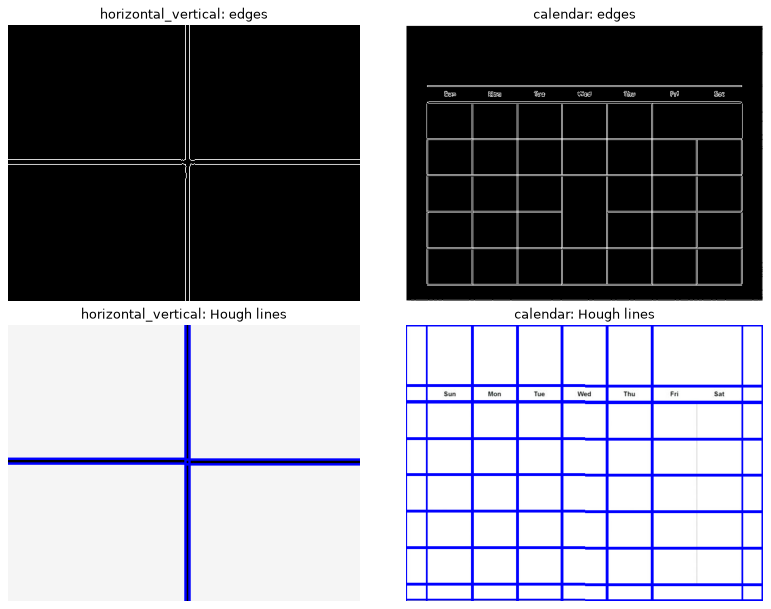

In [4]:
images = {}
edges = {}
for path in INPUT_PATHS:
    images[path.stem] = load_image(path)
    gray = cv2.cvtColor(images[path.stem], cv2.COLOR_BGR2GRAY)
    edges[path.stem] = cv2.Canny(gray, *CANNY_THRESHOLDS)

lines = {}
for name in images:
    lines[name] = hough_lines(edges[name], DEFAULT_THRESHOLD)
    print(f"{name}: {len(lines[name])} lines with at least {DEFAULT_THRESHOLD} votes")

show_images({
    **{f"{name}: edges": edges[name] for name in images},
    **{f"{name}: Hough lines": draw_polar_lines(images[name], lines[name]) for name in images},
}, cols=len(images))

## 6. The threshold controls how many lines are found

A low threshold accepts short or weak lines, and a high threshold keeps only the strongest. The photos below are drawn with each threshold in `THRESHOLDS_TO_TRY`. The count is printed for each one.

horizontal_vertical, threshold 200: 4 lines
horizontal_vertical, threshold 300: 4 lines
horizontal_vertical, threshold 400: 2 lines


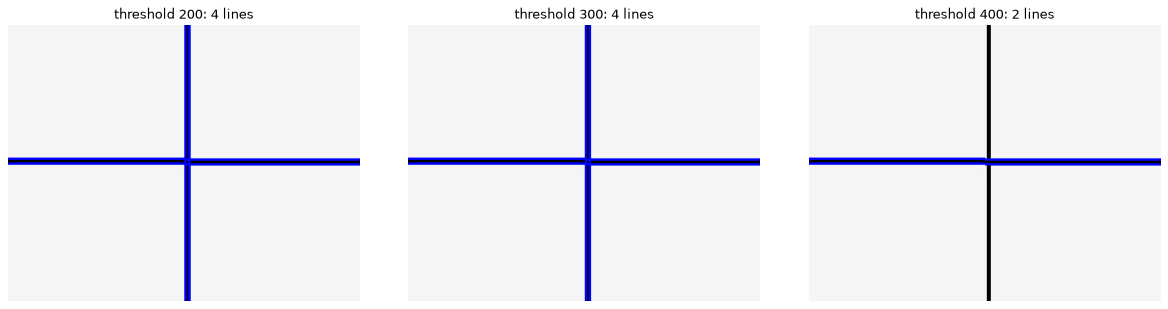

calendar, threshold 200: 34 lines
calendar, threshold 300: 30 lines
calendar, threshold 400: 18 lines


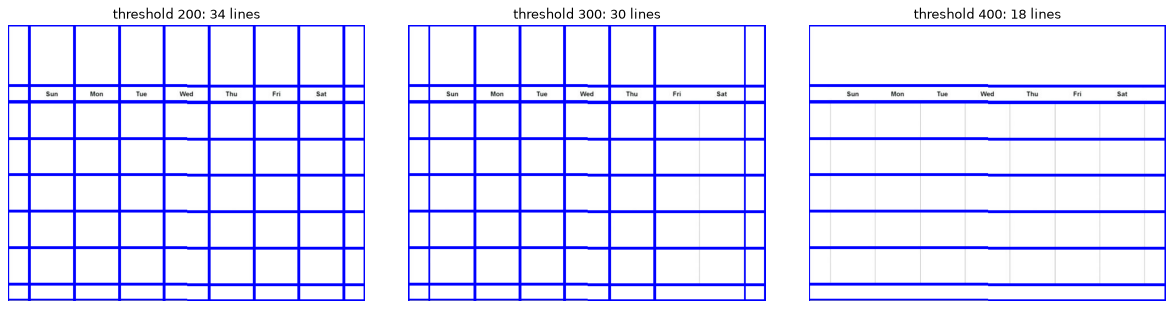

In [5]:
for name in images:
    panels = {}
    for threshold in THRESHOLDS_TO_TRY:
        found = hough_lines(edges[name], threshold)
        print(f"{name}, threshold {threshold}: {len(found)} lines")
        panels[f"threshold {threshold}: {len(found)} lines"] = draw_polar_lines(images[name], found)
    show_images(panels, cols=len(panels))

## 7. Reading the angle of each line

The angle $\theta$ is the angle of the normal to the line, not of the line itself. The line is perpendicular to the normal, so:
- $\theta$ close to 0° means the normal is horizontal, so the line is **vertical**.
- $\theta$ close to 90° means the normal is vertical, so the line is **horizontal**.

The table lists the strongest lines of the first photo with their angles.

In [6]:
name = INPUT_PATHS[0].stem
for rho, theta in lines[name][:8]:
    print(f"rho = {rho:7.1f} px, theta = {np.degrees(theta):6.1f} degrees")

rho =   173.0 px, theta =   90.0 degrees
rho =   167.0 px, theta =   90.0 degrees
rho =   226.0 px, theta =    0.0 degrees
rho =   221.0 px, theta =    0.0 degrees


## 8. Save the results

All results are written to `OUTPUT_DIR`, using the input file name as a prefix.

In [7]:
for name in images:
    save_image(OUTPUT_DIR / f"{name}_edges.jpg", edges[name])
    save_image(OUTPUT_DIR / f"{name}_hough_lines.jpg", draw_polar_lines(images[name], lines[name]))

Saved output/horizontal_vertical_edges.jpg
Saved output/horizontal_vertical_hough_lines.jpg
Saved output/calendar_edges.jpg
Saved output/calendar_hough_lines.jpg


## 9. Conclusion

- The **Hough transform** finds lines by voting in the $(\rho, \theta)$ plane. Edge pixels on the same line add votes to the same cell.
- The **threshold** is the minimum number of votes. Lower values find more lines, including weak or false ones, and higher values keep only the strongest.
- `cv2.HoughLines` returns **infinite lines** with no start or end point. A lane marking is only part of a line, so the probabilistic version `cv2.HoughLinesP` is used for lanes. It returns segments with a start and an end point.
- The method works on edges, so the quality of the Canny edges limits the result.